<a href="https://colab.research.google.com/github/vjshivani25-hub/DLAC/blob/main/skill7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Skill 7: Model Artefact Lifecycle

## Step 1: Install Dependencies

In this step, we install the libraries required to export, validate, and run the trained model using ONNX.

- ONNX: Converts the trained model into a portable computational graph.
- ONNX Runtime: Executes the ONNX model and helps verify its predictions.

PyTorch is already available in Google Colab in most runtimes.

In [1]:
%pip -q install onnx onnxruntime

## 2. Imports and Reproducibility

In this step, we import the libraries required for model training, evaluation, visualization, and artefact conversion.

We set a random seed to make experiments more reproducible. We also check whether a GPU is available to accelerate model training.

The device will automatically be selected as CUDA (GPU) or CPU.

In [2]:
import os
import json
import time
import random
import platform

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Set random seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Automatically select CPU or GPU
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Display environment information
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No CUDA GPU detected.")
    print("TensorRT engine creation may not be available.")

Python: 3.13.18
PyTorch: 2.14.1+cpu
Device: cpu
No CUDA GPU detected.
TensorRT engine creation may not be available.


## 3. Dataset Loading

In this step, we download the CIFAR-10 dataset using torchvision.

CIFAR-10 contains 60,000 color images belonging to 10 classes.
- 50,000 training images
- 10,000 testing images
- Image size: 32 × 32 pixels
- Number of classes: 10

We use the training dataset to train our CNN model and the testing dataset to evaluate its performance.

In [3]:
# Define dataset directory
DATA_DIR = "/content/cifar10_data"

# Convert images into PyTorch tensors
transform = transforms.Compose([
    transforms.ToTensor()
])

# Download training dataset
train_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transform
)

# Download testing dataset
test_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=transform
)

# CIFAR-10 class names
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Dataset downloaded successfully!")
print("-" * 40)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Number of classes:", len(class_names))
print("Image shape:", train_dataset[0][0].shape)

100%|██████████| 170M/170M [35:58<00:00, 79.0kB/s]


Dataset downloaded successfully!
----------------------------------------
Training images: 50000
Testing images: 10000
Number of classes: 10
Image shape: torch.Size([3, 32, 32])


## Step 4: Visualize Dataset Samples

In this step, we visualize sample images from the CIFAR-10 dataset.

The dataset contains 10 different classes. We display 12 sample images along with their corresponding class labels to understand the image data.

This visualization helps us verify that the images are downloaded correctly and that their labels match the objects.

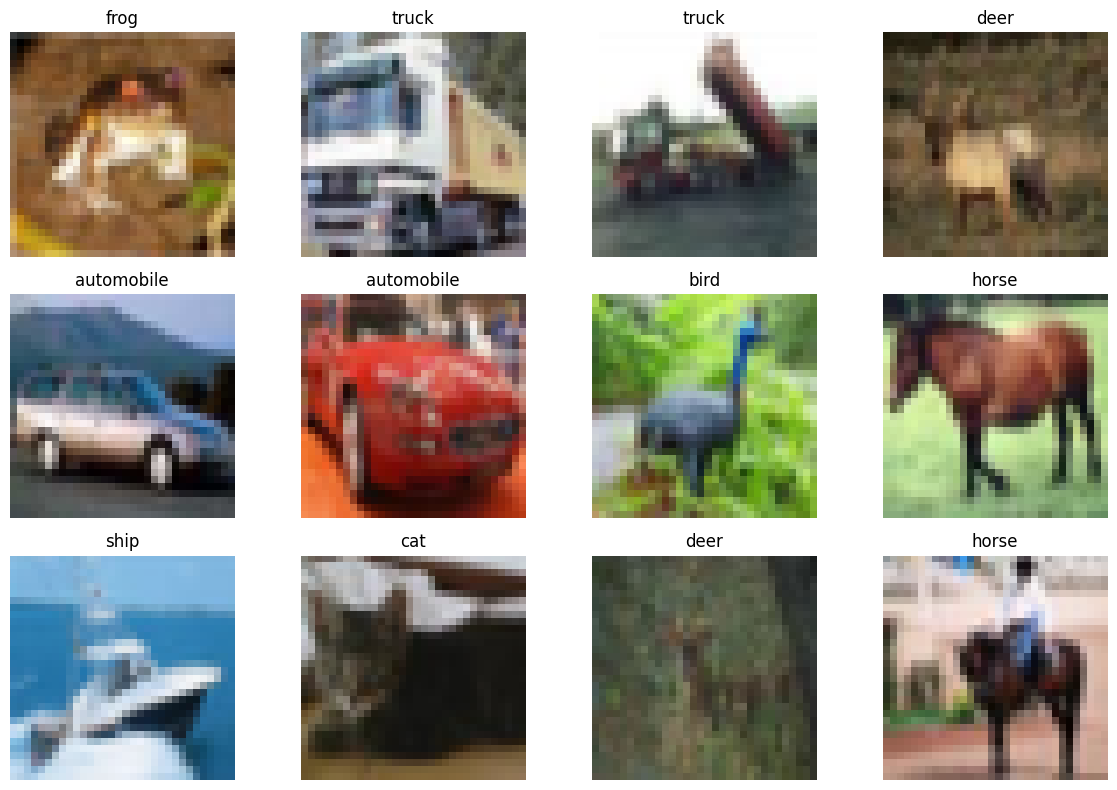

In [4]:
plt.figure(figsize=(12, 8))

for i in range(12):
    image, label = train_dataset[i]

    plt.subplot(3, 4, i + 1)
    plt.imshow(image.permute(1, 2, 0).numpy())
    plt.title(class_names[label])
    plt.axis("off")

plt.tight_layout()
plt.show()

## Step 5: Create DataLoaders

A DataLoader loads images in small batches instead of loading the entire dataset at once.

In this step:
- Batch size is set to 64.
- Training DataLoader shuffles the images.
- Testing DataLoader does not shuffle the images.

DataLoaders make model training more organized and memory-efficient.

In [5]:
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Training batches: 782
Testing batches: 157
Image batch shape: torch.Size([64, 3, 32, 32])
Label batch shape: torch.Size([64])


## Step 6: Define CNN Model Architecture

A Convolutional Neural Network (CNN) is a deep learning model commonly used for image classification.

In this step, we define a CNN architecture containing:

1. Convolutional layers to extract image features.
2. ReLU activation to introduce non-linearity.
3. Max pooling layers to reduce image dimensions.
4. Fully connected layers to perform classification.
5. Output layer with 10 neurons representing the 10 CIFAR-10 classes.

The model accepts RGB images of size 32 × 32 and produces 10 class scores.

In [6]:
class CNNModel(nn.Module):

    def __init__(self, num_classes=10):
        super(CNNModel, self).__init__()

        self.features = nn.Sequential(

            # First convolution block
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolution block
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = CNNModel(num_classes=10).to(DEVICE)

print("CNN model created successfully!")
print(model)

CNN model created successfully!
CNNModel(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=10, bias=True)
  )
)


## Step 7: Model Architecture Analysis

In this step, we analyze the CNN model.

We calculate:
1. Total number of model parameters.
2. Number of trainable parameters.
3. Model input shape.
4. Model output shape.

This information helps us understand the size and structure of our trained model before saving and exporting it.

In [7]:
# Calculate total and trainable parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

# Test model input and output
sample_input = torch.randn(1, 3, 32, 32).to(DEVICE)

model.eval()

with torch.no_grad():
    sample_output = model(sample_input)

print("Model Architecture Analysis")
print("-" * 40)
print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)
print("Number of classes:", sample_output.shape[1])

Model Architecture Analysis
----------------------------------------
Total parameters: 620362
Trainable parameters: 620362
Input shape: torch.Size([1, 3, 32, 32])
Output shape: torch.Size([1, 10])
Number of classes: 10


## Step 8: Train the CNN Model

In this step, we train our CNN model using the CIFAR-10 training dataset.

We use:
- Loss Function: CrossEntropyLoss
- Optimizer: Adam
- Learning Rate: 0.001
- Epochs: 5

An epoch means one complete pass through the training dataset.

The model updates its weights during training to reduce classification errors.

In [8]:
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 5

train_losses = []
train_accuracies = []

print("Starting CNN training...\n")

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        running_loss += loss.item()

        # Calculate training accuracy
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

print("\nCNN training completed successfully!")

Starting CNN training...

Epoch [1/5] Loss: 1.5066 Accuracy: 44.89%
Epoch [2/5] Loss: 1.0887 Accuracy: 61.13%
Epoch [3/5] Loss: 0.9026 Accuracy: 67.94%
Epoch [4/5] Loss: 0.7756 Accuracy: 72.92%
Epoch [5/5] Loss: 0.6788 Accuracy: 76.31%

CNN training completed successfully!


## Step 9: Training Performance Visualization

In this step, we visualize the training loss and training accuracy over 5 epochs.

- Training Loss shows how much error the model makes.
- Training Accuracy shows how many training images the model classifies correctly.

These graphs help us understand how the model learns during training.

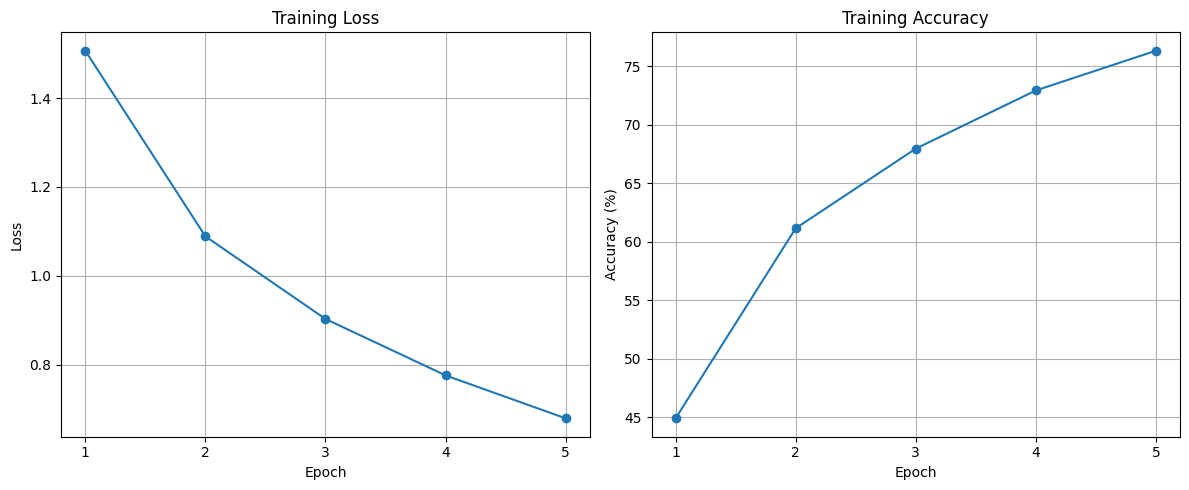

Final Training Loss: 0.6788
Final Training Accuracy: 76.31 %


In [9]:
plt.figure(figsize=(12, 5))

# Training Loss
plt.subplot(1, 2, 1)
plt.plot(range(1, EPOCHS + 1), train_losses, marker='o')
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True)

# Training Accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, EPOCHS + 1), train_accuracies, marker='o')
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True)

plt.tight_layout()
plt.show()

print("Final Training Loss:", round(train_losses[-1], 4))
print("Final Training Accuracy:", round(train_accuracies[-1], 2), "%")

## Step 10: Model Evaluation

In this step, we evaluate the trained CNN model using the CIFAR-10 testing dataset.

We calculate:
1. Test Loss
2. Test Accuracy
3. Correctly Classified Images
4. Total Testing Images

Testing helps us measure the model's ability to classify images it has never seen during training.

In [10]:
model.eval()

test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

average_test_loss = test_loss / len(test_loader)
test_accuracy = 100 * correct / total

print("CNN Model Evaluation")
print("-" * 40)
print("Total testing images:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", total - correct)
print("Test Loss:", round(average_test_loss, 4))
print("Test Accuracy:", round(test_accuracy, 2), "%")

CNN Model Evaluation
----------------------------------------
Total testing images: 10000
Correct predictions: 7238
Incorrect predictions: 2762
Test Loss: 0.8057
Test Accuracy: 72.38 %


## Step 11: Save Trained Model Checkpoint

In this step, we save the trained CNN model in PyTorch checkpoint format (.pth).

The checkpoint contains:
1. Model state dictionary (learned weights).
2. Optimizer state dictionary.
3. Model architecture information.
4. Class names.
5. Training and testing performance.

Saving checkpoints helps us preserve the trained model for future use and deployment.

In [11]:
# Create folder for model artefacts
ARTIFACT_DIR = Path("/content/model_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Save trained model checkpoint
checkpoint = {
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "model_name": "CNNModel",
    "num_classes": 10,
    "class_names": class_names,
    "epochs": EPOCHS,
    "test_accuracy": test_accuracy,
    "test_loss": average_test_loss,
    "train_losses": train_losses,
    "train_accuracies": train_accuracies,
    "input_shape": [1, 3, 32, 32],
    "seed": SEED
}

checkpoint_path = ARTIFACT_DIR / "cifar10_cnn_checkpoint.pth"

torch.save(checkpoint, checkpoint_path)

print("Model checkpoint saved successfully!")
print("Checkpoint location:", checkpoint_path)
print("File size:", round(checkpoint_path.stat().st_size / (1024 * 1024), 2), "MB")

Model checkpoint saved successfully!
Checkpoint location: /content/model_artifacts/cifar10_cnn_checkpoint.pth
File size: 7.11 MB


## Step 12: Reload and Verify Model Checkpoint

In this step, we reload the saved PyTorch checkpoint.

We:
1. Load the checkpoint file.
2. Create a new CNN model.
3. Restore the saved model weights.
4. Perform a sample prediction.
5. Verify the model output shape.

This confirms that our trained model can be reused without training it again.

In [12]:
# Load saved checkpoint
loaded_checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

# Create a fresh CNN model
reloaded_model = CNNModel(num_classes=10).to(DEVICE)

# Restore saved weights
reloaded_model.load_state_dict(
    loaded_checkpoint["model_state_dict"]
)

reloaded_model.eval()

# Test the reloaded model
sample_image, sample_label = test_dataset[0]

sample_input = sample_image.unsqueeze(0).to(DEVICE)

with torch.no_grad():
    prediction = reloaded_model(sample_input)

predicted_class = torch.argmax(prediction, dim=1).item()

print("Checkpoint loaded successfully!")
print("Original class:", class_names[sample_label])
print("Predicted class:", class_names[predicted_class])
print("Model output shape:", prediction.shape)
print("Saved test accuracy:", loaded_checkpoint["test_accuracy"])

Checkpoint loaded successfully!
Original class: cat
Predicted class: cat
Model output shape: torch.Size([1, 10])
Saved test accuracy: 72.38


## Step 13: Export CNN Model to ONNX

In this step, we convert our trained CNN model from PyTorch format (.pth) into ONNX format (.onnx).

ONNX is an open model format that supports interoperability between different deep learning frameworks.

We:
1. Load the trained model.
2. Create a sample input tensor.
3. Export the model into ONNX format.
4. Save the ONNX graph for later inference and optimization.

The exported ONNX model will accept RGB images of shape (1, 3, 32, 32) and produce 10 class scores.

In [13]:
# Prepare model for ONNX export
reloaded_model.eval()

dummy_input = torch.randn(1, 3, 32, 32).to(DEVICE)

onnx_path = ARTIFACT_DIR / "cifar10_cnn.onnx"

# Export PyTorch model to ONNX
torch.onnx.export(
    reloaded_model,
    dummy_input,
    str(onnx_path),
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["output"],
    dynamic_axes={
        "input": {0: "batch_size"},
        "output": {0: "batch_size"}
    },
    dynamo=False
)

print("ONNX export completed successfully!")
print("ONNX file location:", onnx_path)
print("ONNX file size:", round(onnx_path.stat().st_size / (1024 * 1024), 2), "MB")

ONNX export completed successfully!
ONNX file location: /content/model_artifacts/cifar10_cnn.onnx
ONNX file size: 2.37 MB


/tmp/ipykernel_1682/1707855461.py:9: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


## Step 14: ONNX Graph Validation

In this step, we validate the exported ONNX model.

We:
1. Load the ONNX model.
2. Check the model structure.
3. Verify that the graph passes ONNX validation.
4. Display the model input and output information.

This ensures that the exported ONNX graph is ready for inference using ONNX Runtime.

In [14]:
import onnx

# Load ONNX model
onnx_model = onnx.load(str(onnx_path))

# Validate ONNX graph
onnx.checker.check_model(onnx_model)

print("ONNX graph validation successful!")
print("-" * 40)

print("ONNX IR Version:", onnx_model.ir_version)
print("ONNX Opset Version:", onnx_model.opset_import[0].version)

print("\nModel Inputs:")
for input_info in onnx_model.graph.input:
    print(input_info.name)

print("\nModel Outputs:")
for output_info in onnx_model.graph.output:
    print(output_info.name)

print("\nONNX graph is valid and ready for inference!")

ONNX graph validation successful!
----------------------------------------
ONNX IR Version: 8
ONNX Opset Version: 17

Model Inputs:
input

Model Outputs:
output

ONNX graph is valid and ready for inference!


## Step 15: ONNX Runtime Inference

ONNX Runtime is an inference engine used to execute ONNX models.

In this step, we:
1. Load the exported ONNX model.
2. Create an ONNX Runtime inference session.
3. Pass a test image to the ONNX model.
4. Generate a prediction.
5. Display the predicted class.

This verifies that the ONNX model works correctly for image classification.

In [15]:
import onnxruntime as ort

# Create ONNX Runtime inference session
onnx_session = ort.InferenceSession(
    str(onnx_path),
    providers=["CPUExecutionProvider"]
)

# Get a test image
test_image, true_label = test_dataset[0]

# Prepare input as NumPy array
onnx_input = test_image.unsqueeze(0).numpy()

# Run ONNX inference
onnx_outputs = onnx_session.run(
    ["output"],
    {"input": onnx_input}
)

# Get predicted class
onnx_prediction = np.argmax(onnx_outputs[0], axis=1)[0]

print("ONNX Runtime inference successful!")
print("-" * 40)
print("True class:", class_names[true_label])
print("Predicted class:", class_names[onnx_prediction])
print("Output shape:", onnx_outputs[0].shape)
print("Execution provider:", onnx_session.get_providers())

ONNX Runtime inference successful!
----------------------------------------
True class: cat
Predicted class: cat
Output shape: (1, 10)
Execution provider: ['CPUExecutionProvider']


## Step 16: PyTorch and ONNX Comparison

In this step, we compare the outputs of the trained PyTorch model and the exported ONNX model.

We:
1. Pass the same test image to both models.
2. Collect their prediction scores.
3. Compare their predicted classes.
4. Calculate the maximum difference between their output scores.

This verifies that the ONNX conversion preserves the original model's behavior.

In [16]:
# Prepare the same test image
test_image, true_label = test_dataset[0]

pytorch_input = test_image.unsqueeze(0).to(DEVICE)
onnx_input = test_image.unsqueeze(0).numpy()

# PyTorch prediction
reloaded_model.eval()

with torch.no_grad():
    pytorch_output = reloaded_model(pytorch_input)

pytorch_scores = pytorch_output.cpu().numpy()

# ONNX prediction
onnx_scores = onnx_session.run(
    ["output"],
    {"input": onnx_input}
)[0]

# Compare predictions
pytorch_class = np.argmax(pytorch_scores, axis=1)[0]
onnx_class = np.argmax(onnx_scores, axis=1)[0]

max_difference = np.max(
    np.abs(pytorch_scores - onnx_scores)
)

print("PyTorch vs ONNX Comparison")
print("-" * 40)
print("True class:", class_names[true_label])
print("PyTorch prediction:", class_names[pytorch_class])
print("ONNX prediction:", class_names[onnx_class])
print("Maximum output difference:", max_difference)

if np.allclose(pytorch_scores, onnx_scores, rtol=1e-3, atol=1e-5):
    print("\nValidation successful: Outputs are numerically close.")
else:
    print("\nWarning: Outputs differ beyond the selected tolerance.")

PyTorch vs ONNX Comparison
----------------------------------------
True class: cat
PyTorch prediction: cat
ONNX prediction: cat
Maximum output difference: 9.536743e-07

Validation successful: Outputs are numerically close.


## Step 17: TensorRT Availability Check

TensorRT is an NVIDIA deep learning inference optimization framework.

It helps improve model inference speed and optimize GPU execution.

In this step, we:
1. Check whether an NVIDIA GPU is available.
2. Check whether the TensorRT library is installed.
3. Display the TensorRT version if available.

This verification determines whether we can build a TensorRT engine in the current environment.

In [17]:
import importlib.util

print("TensorRT Environment Check")
print("-" * 40)

print("CUDA GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

if importlib.util.find_spec("tensorrt") is not None:
    import tensorrt as trt

    print("TensorRT is installed.")
    print("TensorRT version:", trt.__version__)
    TENSORRT_AVAILABLE = True

else:
    print("TensorRT is not installed in this environment.")
    TENSORRT_AVAILABLE = False

print("-" * 40)

if TENSORRT_AVAILABLE and torch.cuda.is_available():
    print("Environment supports TensorRT engine creation.")
else:
    print("TensorRT engine creation is not available right now.")

TensorRT Environment Check
----------------------------------------
CUDA GPU available: False
TensorRT is not installed in this environment.
----------------------------------------
TensorRT engine creation is not available right now.


## Step 18: TensorRT Engine Generation Status

TensorRT engine generation requires a compatible NVIDIA GPU and TensorRT installation.

In our current Google Colab environment:
- CUDA GPU is unavailable.
- TensorRT library is not installed.
- ONNX model has been successfully exported and validated.

Therefore, TensorRT engine generation is skipped in this environment.

The validated ONNX model is preserved as the input artifact for future TensorRT conversion on a compatible NVIDIA GPU system.

This documents the deployment limitation without claiming an engine was generated.

In [18]:
print("TensorRT Engine Generation Report")
print("-" * 45)

print("ONNX model available:", onnx_path.exists())
print("CUDA GPU available:", torch.cuda.is_available())
print("TensorRT available:", TENSORRT_AVAILABLE)

if onnx_path.exists() and not TENSORRT_AVAILABLE:
    print("\nTensorRT engine generation: SKIPPED")
    print("Reason: Compatible TensorRT environment unavailable.")
    print("Available deployment artifact: ONNX model")

elif onnx_path.exists() and TENSORRT_AVAILABLE and torch.cuda.is_available():
    print("\nEnvironment is ready for TensorRT conversion.")

print("-" * 45)

TensorRT Engine Generation Report
---------------------------------------------
ONNX model available: True
CUDA GPU available: False
TensorRT available: False

TensorRT engine generation: SKIPPED
Reason: Compatible TensorRT environment unavailable.
Available deployment artifact: ONNX model
---------------------------------------------


## Step 19: Inference Performance Benchmarking

In this step, we measure the inference time of the PyTorch and ONNX models.

We:
1. Use the same test image for both models.
2. Run multiple inference iterations.
3. Measure the average execution time.
4. Compare PyTorch and ONNX Runtime performance.

This helps us understand the effect of using ONNX Runtime for model deployment.

In [19]:
# Prepare input image
test_image, _ = test_dataset[0]

pytorch_input = test_image.unsqueeze(0).to(DEVICE)
onnx_input = test_image.unsqueeze(0).numpy()

NUM_RUNS = 100

# Warm-up
with torch.no_grad():
    for _ in range(10):
        reloaded_model(pytorch_input)

for _ in range(10):
    onnx_session.run(["output"], {"input": onnx_input})

# Benchmark PyTorch
pytorch_start = time.perf_counter()

with torch.no_grad():
    for _ in range(NUM_RUNS):
        reloaded_model(pytorch_input)

pytorch_end = time.perf_counter()

# Benchmark ONNX Runtime
onnx_start = time.perf_counter()

for _ in range(NUM_RUNS):
    onnx_session.run(["output"], {"input": onnx_input})

onnx_end = time.perf_counter()

# Calculate average latency in milliseconds
pytorch_latency = (
    (pytorch_end - pytorch_start) / NUM_RUNS
) * 1000

onnx_latency = (
    (onnx_end - onnx_start) / NUM_RUNS
) * 1000

print("Inference Performance Comparison")
print("-" * 45)
print("Number of runs:", NUM_RUNS)
print("PyTorch average latency:", round(pytorch_latency, 4), "ms")
print("ONNX average latency:", round(onnx_latency, 4), "ms")

if onnx_latency < pytorch_latency:
    print("ONNX Runtime was faster in this benchmark.")
else:
    print("PyTorch was faster in this benchmark.")

Inference Performance Comparison
---------------------------------------------
Number of runs: 100
PyTorch average latency: 1.2716 ms
ONNX average latency: 0.4657 ms
ONNX Runtime was faster in this benchmark.


## Step 20: Model Artefact Organization and Verification

In this step, we organize and verify the generated model artefacts.

Our project produces:
1. PyTorch trained checkpoint (.pth).
2. ONNX model graph (.onnx).
3. Model performance information.
4. Training configuration and metadata.

The TensorRT engine is not generated because the current environment does not have a compatible NVIDIA GPU and TensorRT installation.

We verify the available files before creating the final project package.

In [20]:
# Verify generated model artefacts

print("MODEL ARTIFACT VERIFICATION")
print("=" * 50)

artifact_files = list(ARTIFACT_DIR.iterdir())

for file in artifact_files:
    if file.is_file():
        size_mb = file.stat().st_size / (1024 * 1024)

        print("File:", file.name)
        print("Size:", round(size_mb, 3), "MB")
        print("Status:", "Available" if file.exists() else "Missing")
        print("-" * 30)

print("\nFinal Verification")
print("PyTorch checkpoint:", checkpoint_path.exists())
print("ONNX graph:", onnx_path.exists())
print("TensorRT engine:", False)

MODEL ARTIFACT VERIFICATION
File: cifar10_cnn.onnx
Size: 2.369 MB
Status: Available
------------------------------
File: cifar10_cnn_checkpoint.pth
Size: 7.113 MB
Status: Available
------------------------------

Final Verification
PyTorch checkpoint: True
ONNX graph: True
TensorRT engine: False


## Step 21: Save Model Metadata

In this step, we save the model information in JSON format.

The metadata contains:
1. Model name and architecture.
2. Dataset information.
3. Training configuration.
4. Testing accuracy and loss.
5. PyTorch and ONNX inference latency.
6. TensorRT generation status.

This metadata helps maintain documentation of the complete model artefact lifecycle.

In [21]:
metadata = {
    "project_name": "CIFAR-10 CNN Model Artefact Lifecycle",
    "model_name": "CNNModel",
    "architecture": {
        "input_shape": [1, 3, 32, 32],
        "output_classes": 10,
        "layers": [
            "Conv2D",
            "ReLU",
            "MaxPooling",
            "Conv2D",
            "ReLU",
            "MaxPooling",
            "Conv2D",
            "ReLU",
            "MaxPooling",
            "Flatten",
            "Fully Connected"
        ],
        "total_parameters": total_params
    },
    "dataset": {
        "name": "CIFAR-10",
        "training_images": len(train_dataset),
        "testing_images": len(test_dataset),
        "number_of_classes": len(class_names),
        "class_names": class_names
    },
    "training": {
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "training_accuracy": train_accuracies[-1],
        "test_accuracy": test_accuracy,
        "test_loss": average_test_loss
    },
    "inference_benchmark": {
        "runs": NUM_RUNS,
        "pytorch_latency_ms": pytorch_latency,
        "onnx_latency_ms": onnx_latency
    },
    "artifacts": {
        "pytorch_checkpoint": checkpoint_path.name,
        "onnx_model": onnx_path.name,
        "tensorrt_engine": None,
        "tensorrt_status": "Skipped - compatible GPU and TensorRT unavailable"
    }
}

metadata_path = ARTIFACT_DIR / "model_metadata.json"

with open(metadata_path, "w") as file:
    json.dump(metadata, file, indent=4)

print("Model metadata saved successfully!")
print("Metadata location:", metadata_path)

print("\nMetadata preview:")
print(json.dumps(metadata, indent=4))

Model metadata saved successfully!
Metadata location: /content/model_artifacts/model_metadata.json

Metadata preview:
{
    "project_name": "CIFAR-10 CNN Model Artefact Lifecycle",
    "model_name": "CNNModel",
    "architecture": {
        "input_shape": [
            1,
            3,
            32,
            32
        ],
        "output_classes": 10,
        "layers": [
            "Conv2D",
            "ReLU",
            "MaxPooling",
            "Conv2D",
            "ReLU",
            "MaxPooling",
            "Conv2D",
            "ReLU",
            "MaxPooling",
            "Flatten",
            "Fully Connected"
        ],
        "total_parameters": 620362
    },
    "dataset": {
        "name": "CIFAR-10",
        "training_images": 50000,
        "testing_images": 10000,
        "number_of_classes": 10,
        "class_names": [
            "airplane",
            "automobile",
            "bird",
            "cat",
            "deer",
            "dog",
            

## Step 22: Create Final Model Artefact Package

In this step, we create a ZIP package containing all the generated model artefacts.

The package includes:
1. Trained PyTorch checkpoint (.pth).
2. Exported ONNX graph (.onnx).
3. Model metadata (.json).

The TensorRT engine is excluded because it could not be generated in the current environment.

This ZIP package makes it easy to store and transfer the model artefacts.

In [22]:
import zipfile

zip_path = Path("/content/CIFAR10_Model_Artifacts.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:

    for file in ARTIFACT_DIR.iterdir():
        if file.is_file():
            zip_file.write(file, arcname=file.name)

print("ZIP package created successfully!")
print("ZIP location:", zip_path)
print("ZIP size:", round(zip_path.stat().st_size / (1024 * 1024), 2), "MB")

print("\nFiles included in ZIP:")

with zipfile.ZipFile(zip_path, "r") as zip_file:
    for name in zip_file.namelist():
        print("-", name)

ZIP package created successfully!
ZIP location: /content/CIFAR10_Model_Artifacts.zip
ZIP size: 7.21 MB

Files included in ZIP:
- model_metadata.json
- cifar10_cnn.onnx
- cifar10_cnn_checkpoint.pth


## Step 23: Final Verification and Download

In this final step, we verify the generated model artefacts and download the complete ZIP package.

We check:
1. PyTorch checkpoint availability.
2. ONNX graph availability.
3. Model metadata availability.
4. Final ZIP package availability.

After verification, we download the ZIP package for future use.

In [23]:
from google.colab import files

print("FINAL MODEL ARTIFACT VERIFICATION")
print("=" * 45)

required_files = [
    checkpoint_path,
    onnx_path,
    metadata_path,
    zip_path
]

all_available = True

for file in required_files:
    status = file.exists()

    print(file.name, ":", "AVAILABLE" if status else "MISSING")

    if not status:
        all_available = False

print("=" * 45)

if all_available:
    print("All required artefacts verified successfully!")
    print("\nDownloading final ZIP package...")

    files.download(str(zip_path))

else:
    print("Some artefacts are missing. Please check the previous steps.")

FINAL MODEL ARTIFACT VERIFICATION
cifar10_cnn_checkpoint.pth : AVAILABLE
cifar10_cnn.onnx : AVAILABLE
model_metadata.json : AVAILABLE
CIFAR10_Model_Artifacts.zip : AVAILABLE
All required artefacts verified successfully!



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>